Fitting 5 folds for each of 80 candidates, totalling 400 fits
Best parameters: {'n_neighbors': 3, 'p': 2, 'weights': 'distance'}
Best CV R²: 0.707035759283879

KNN Regression Test Performance:
-------------------------------
R²: 0.831022140463288
MAE: 0.031020446762548948
MSE: 0.0027143727949454316
RMSE: 0.052099642944510006


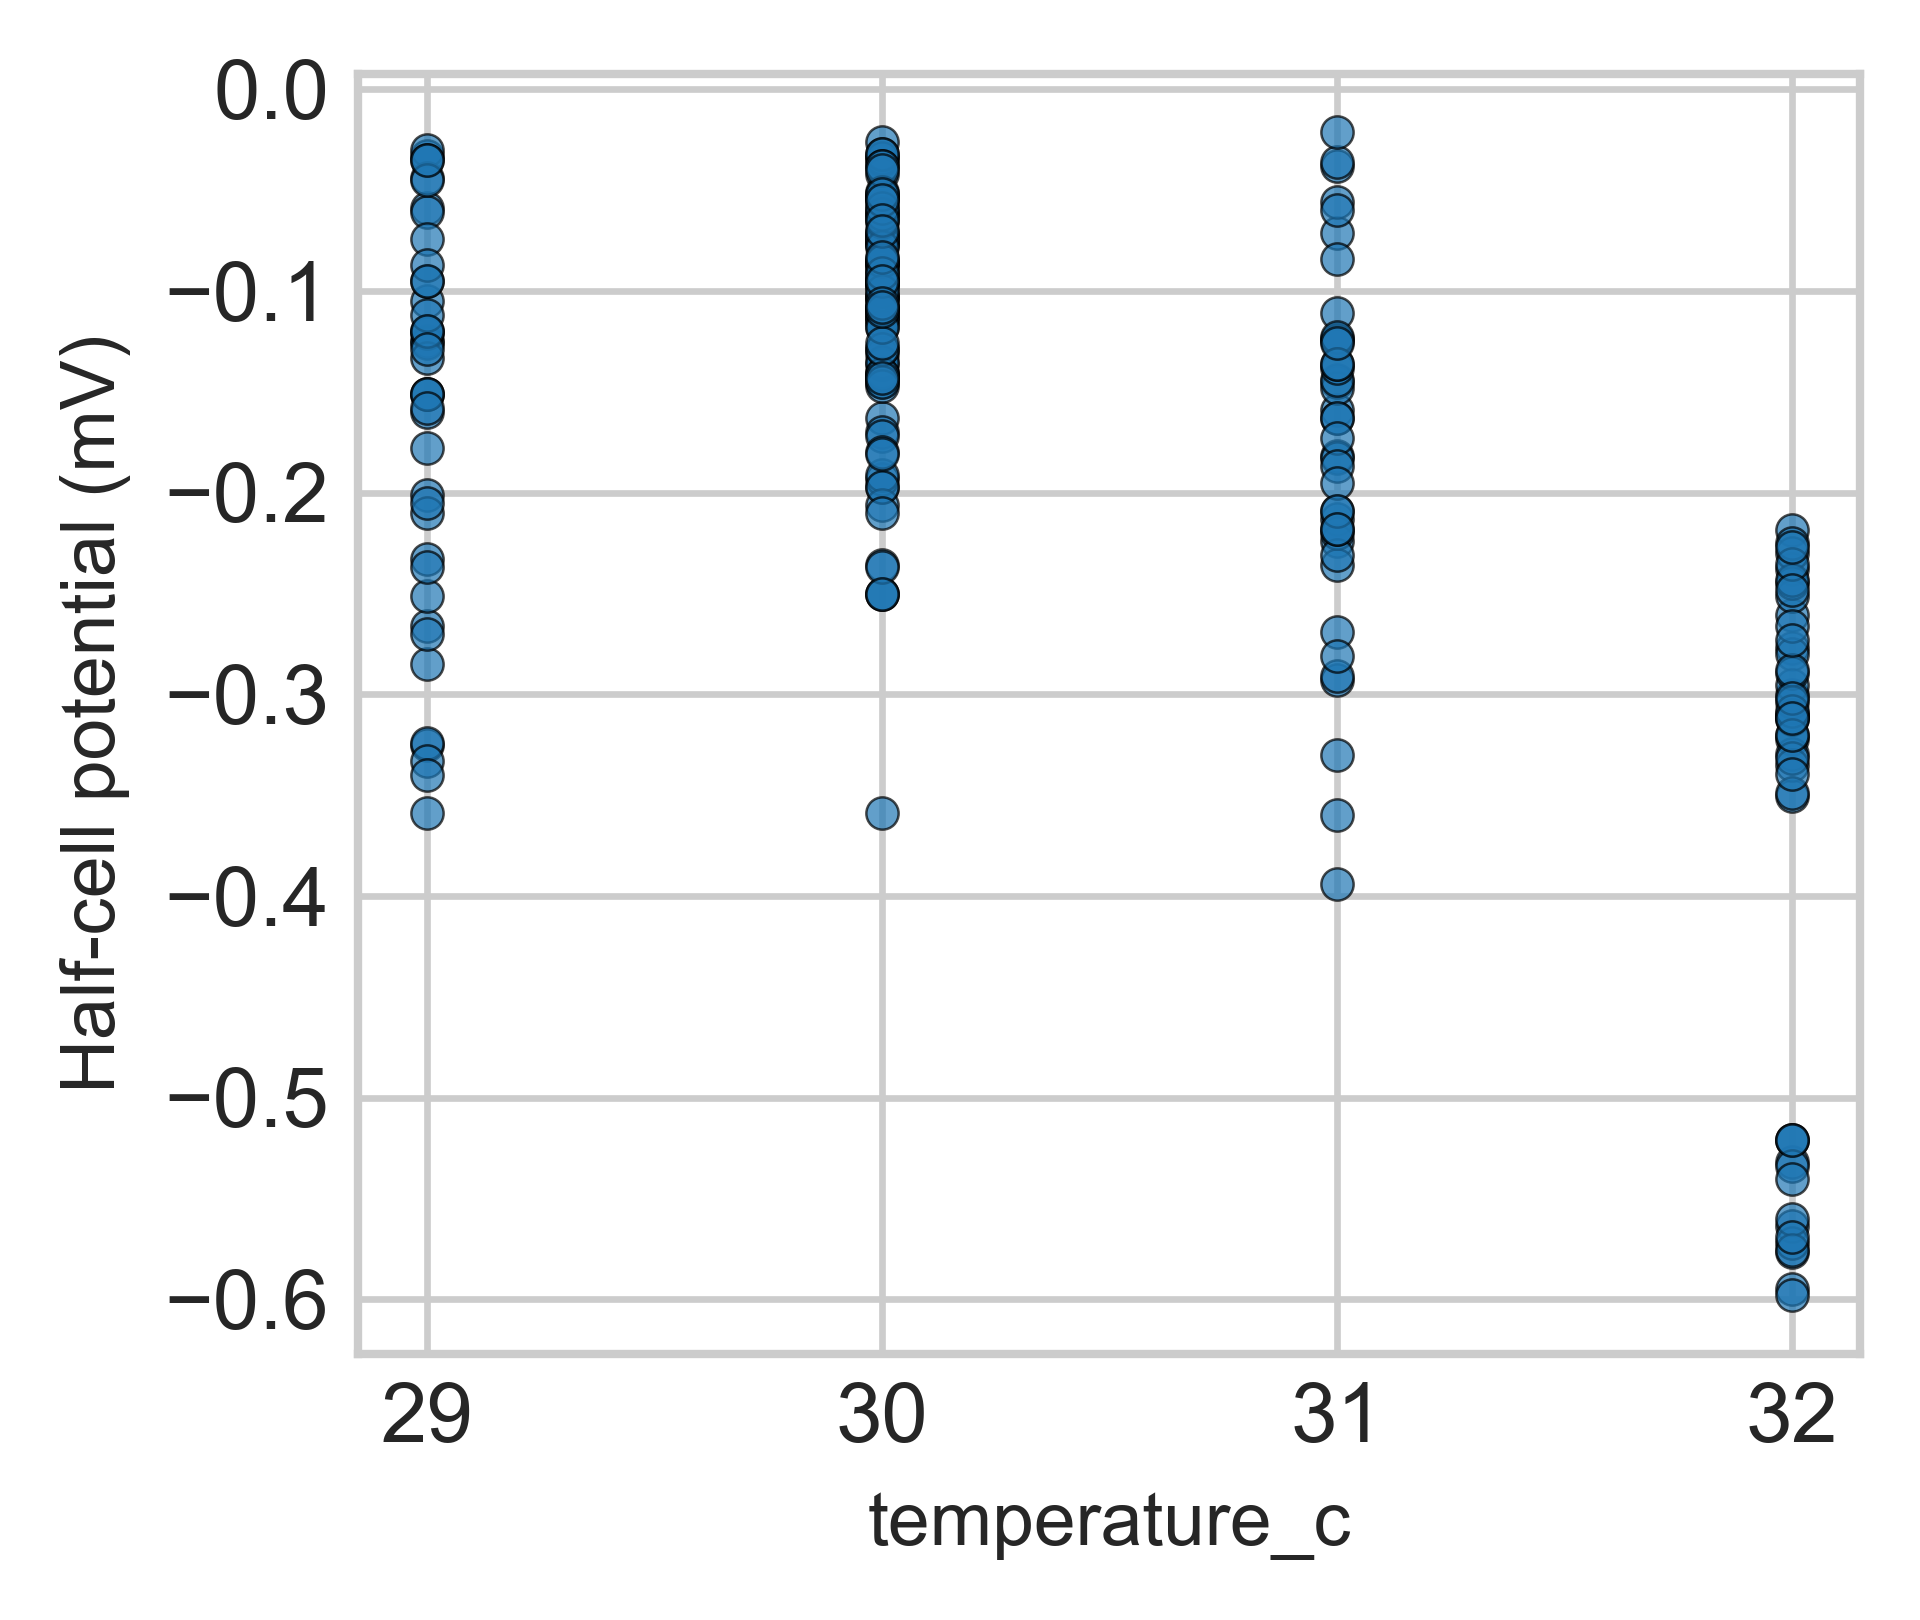

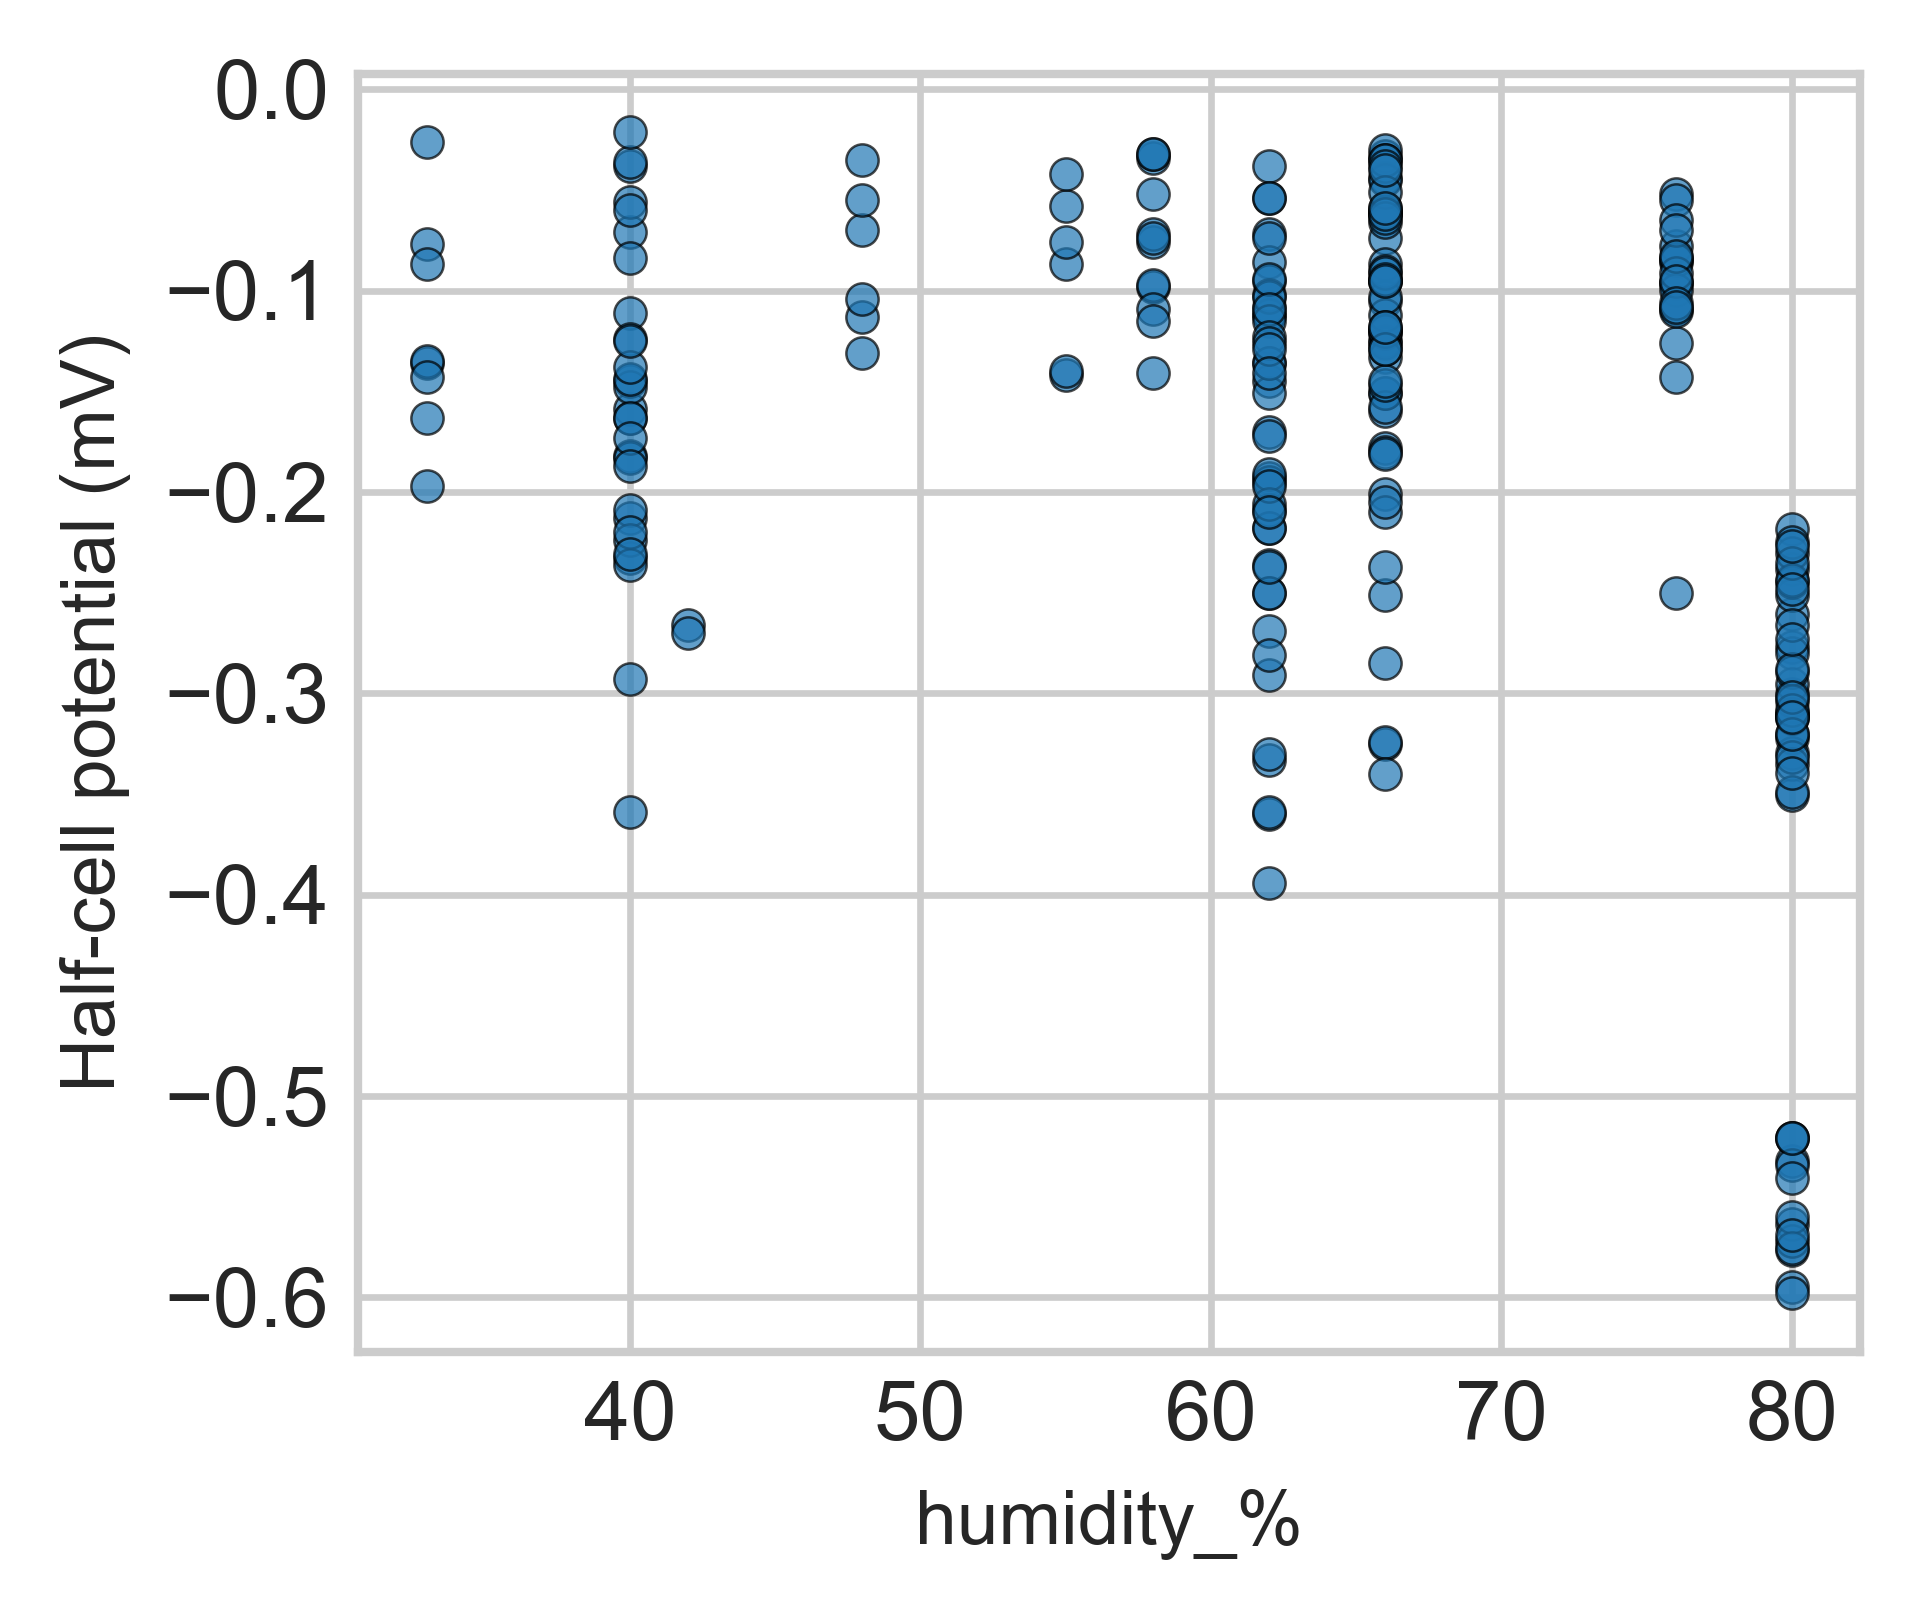

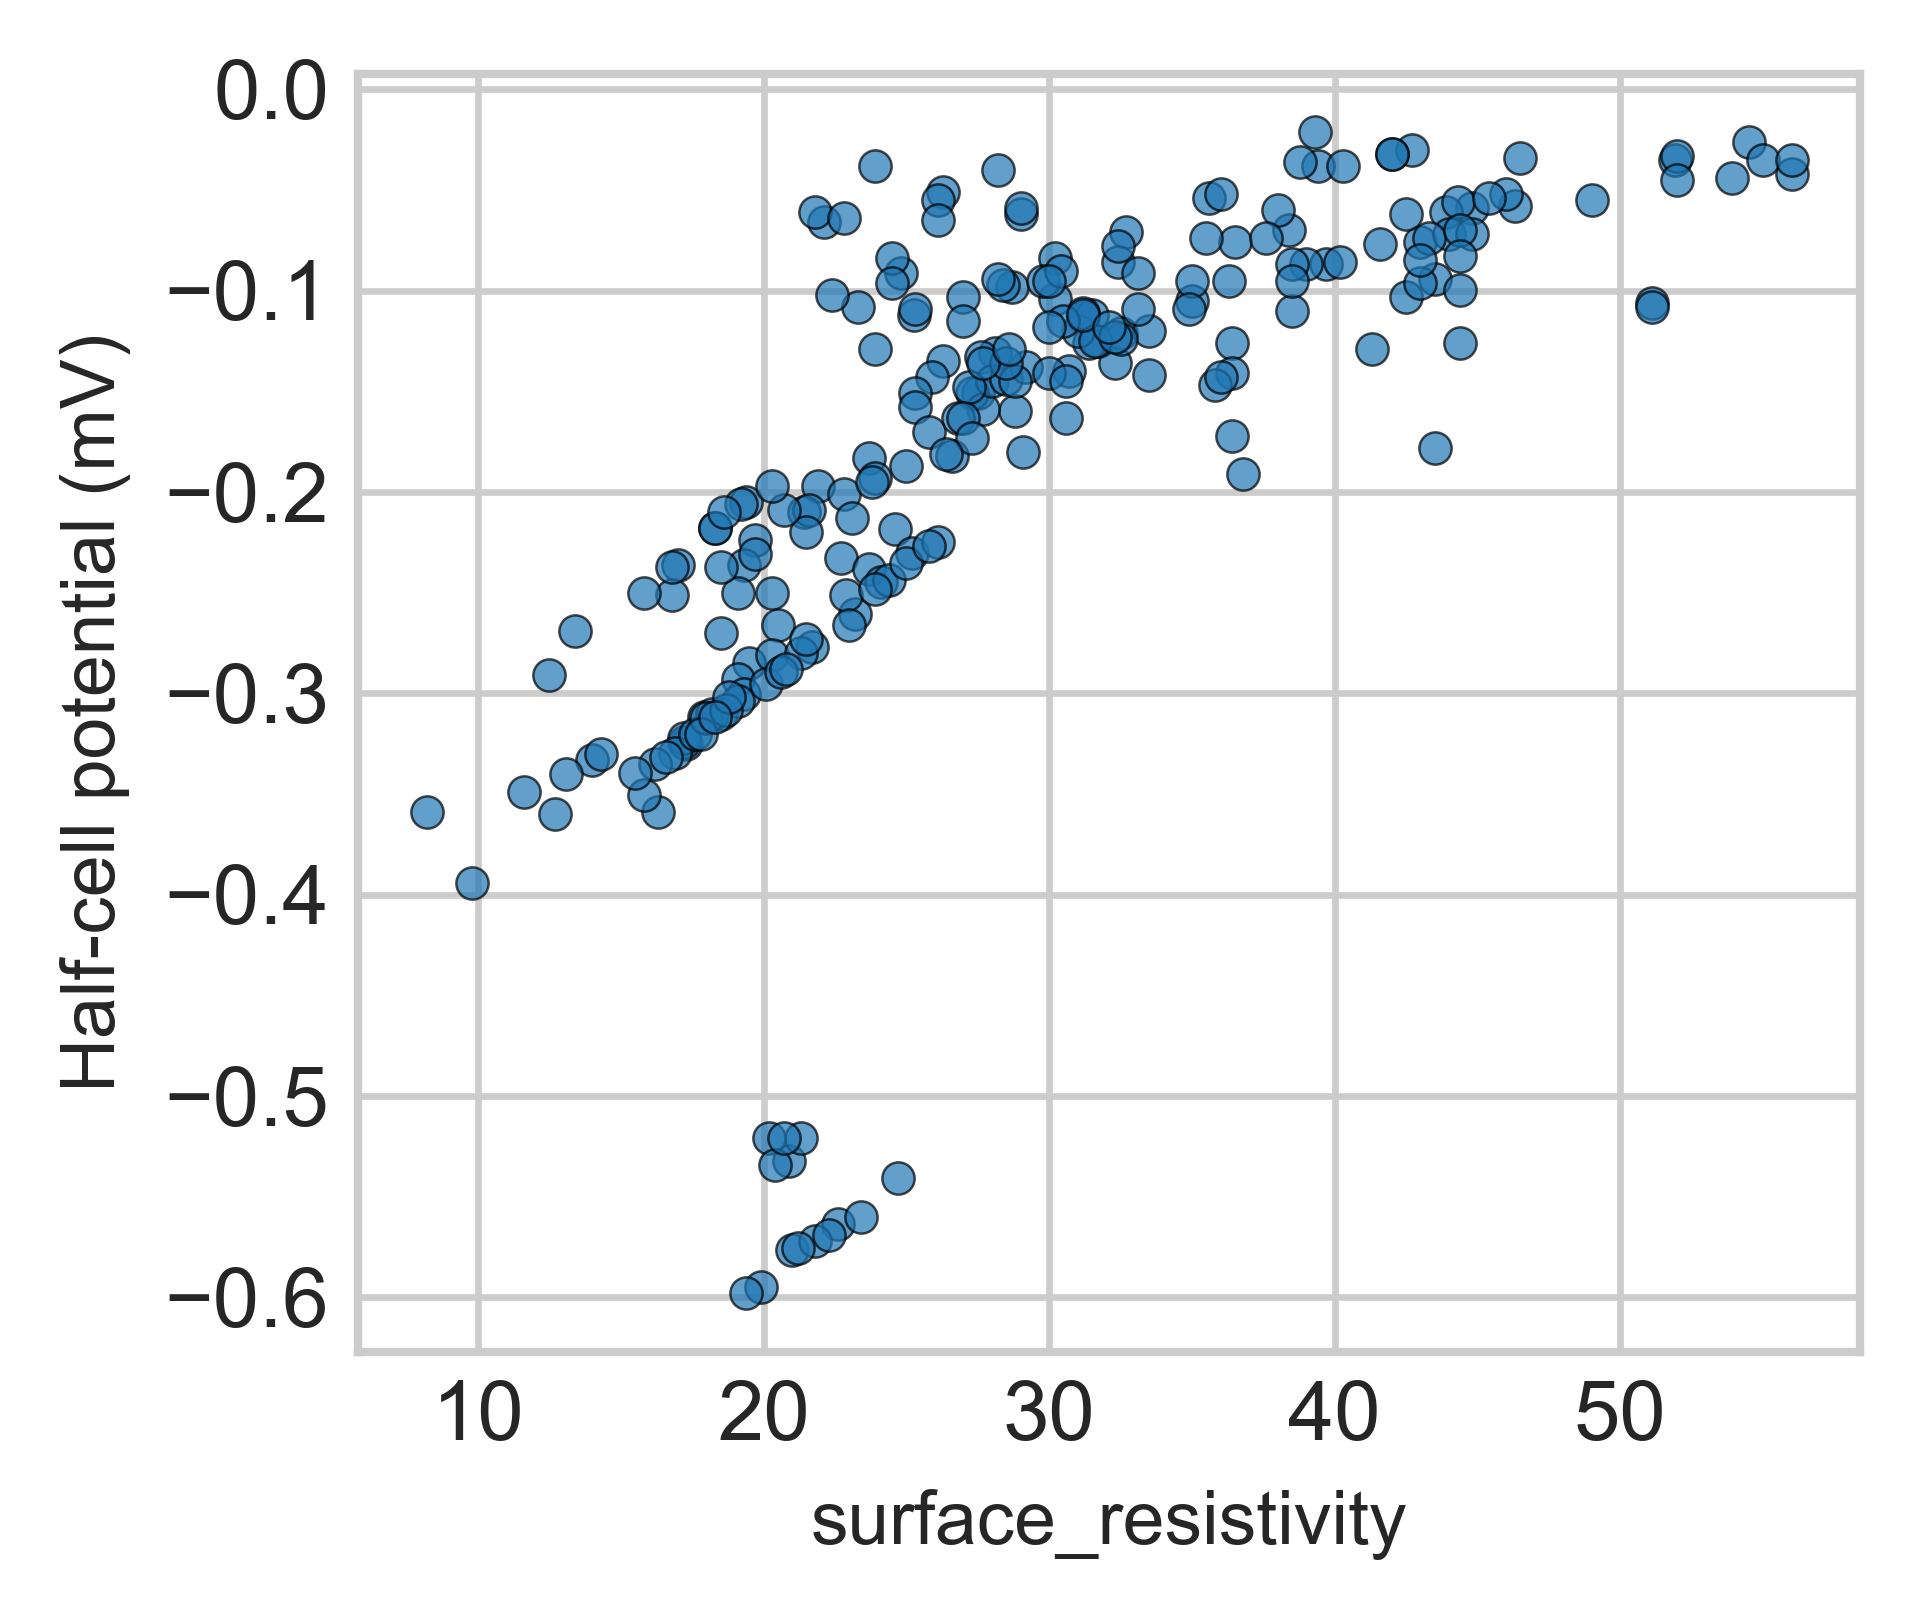

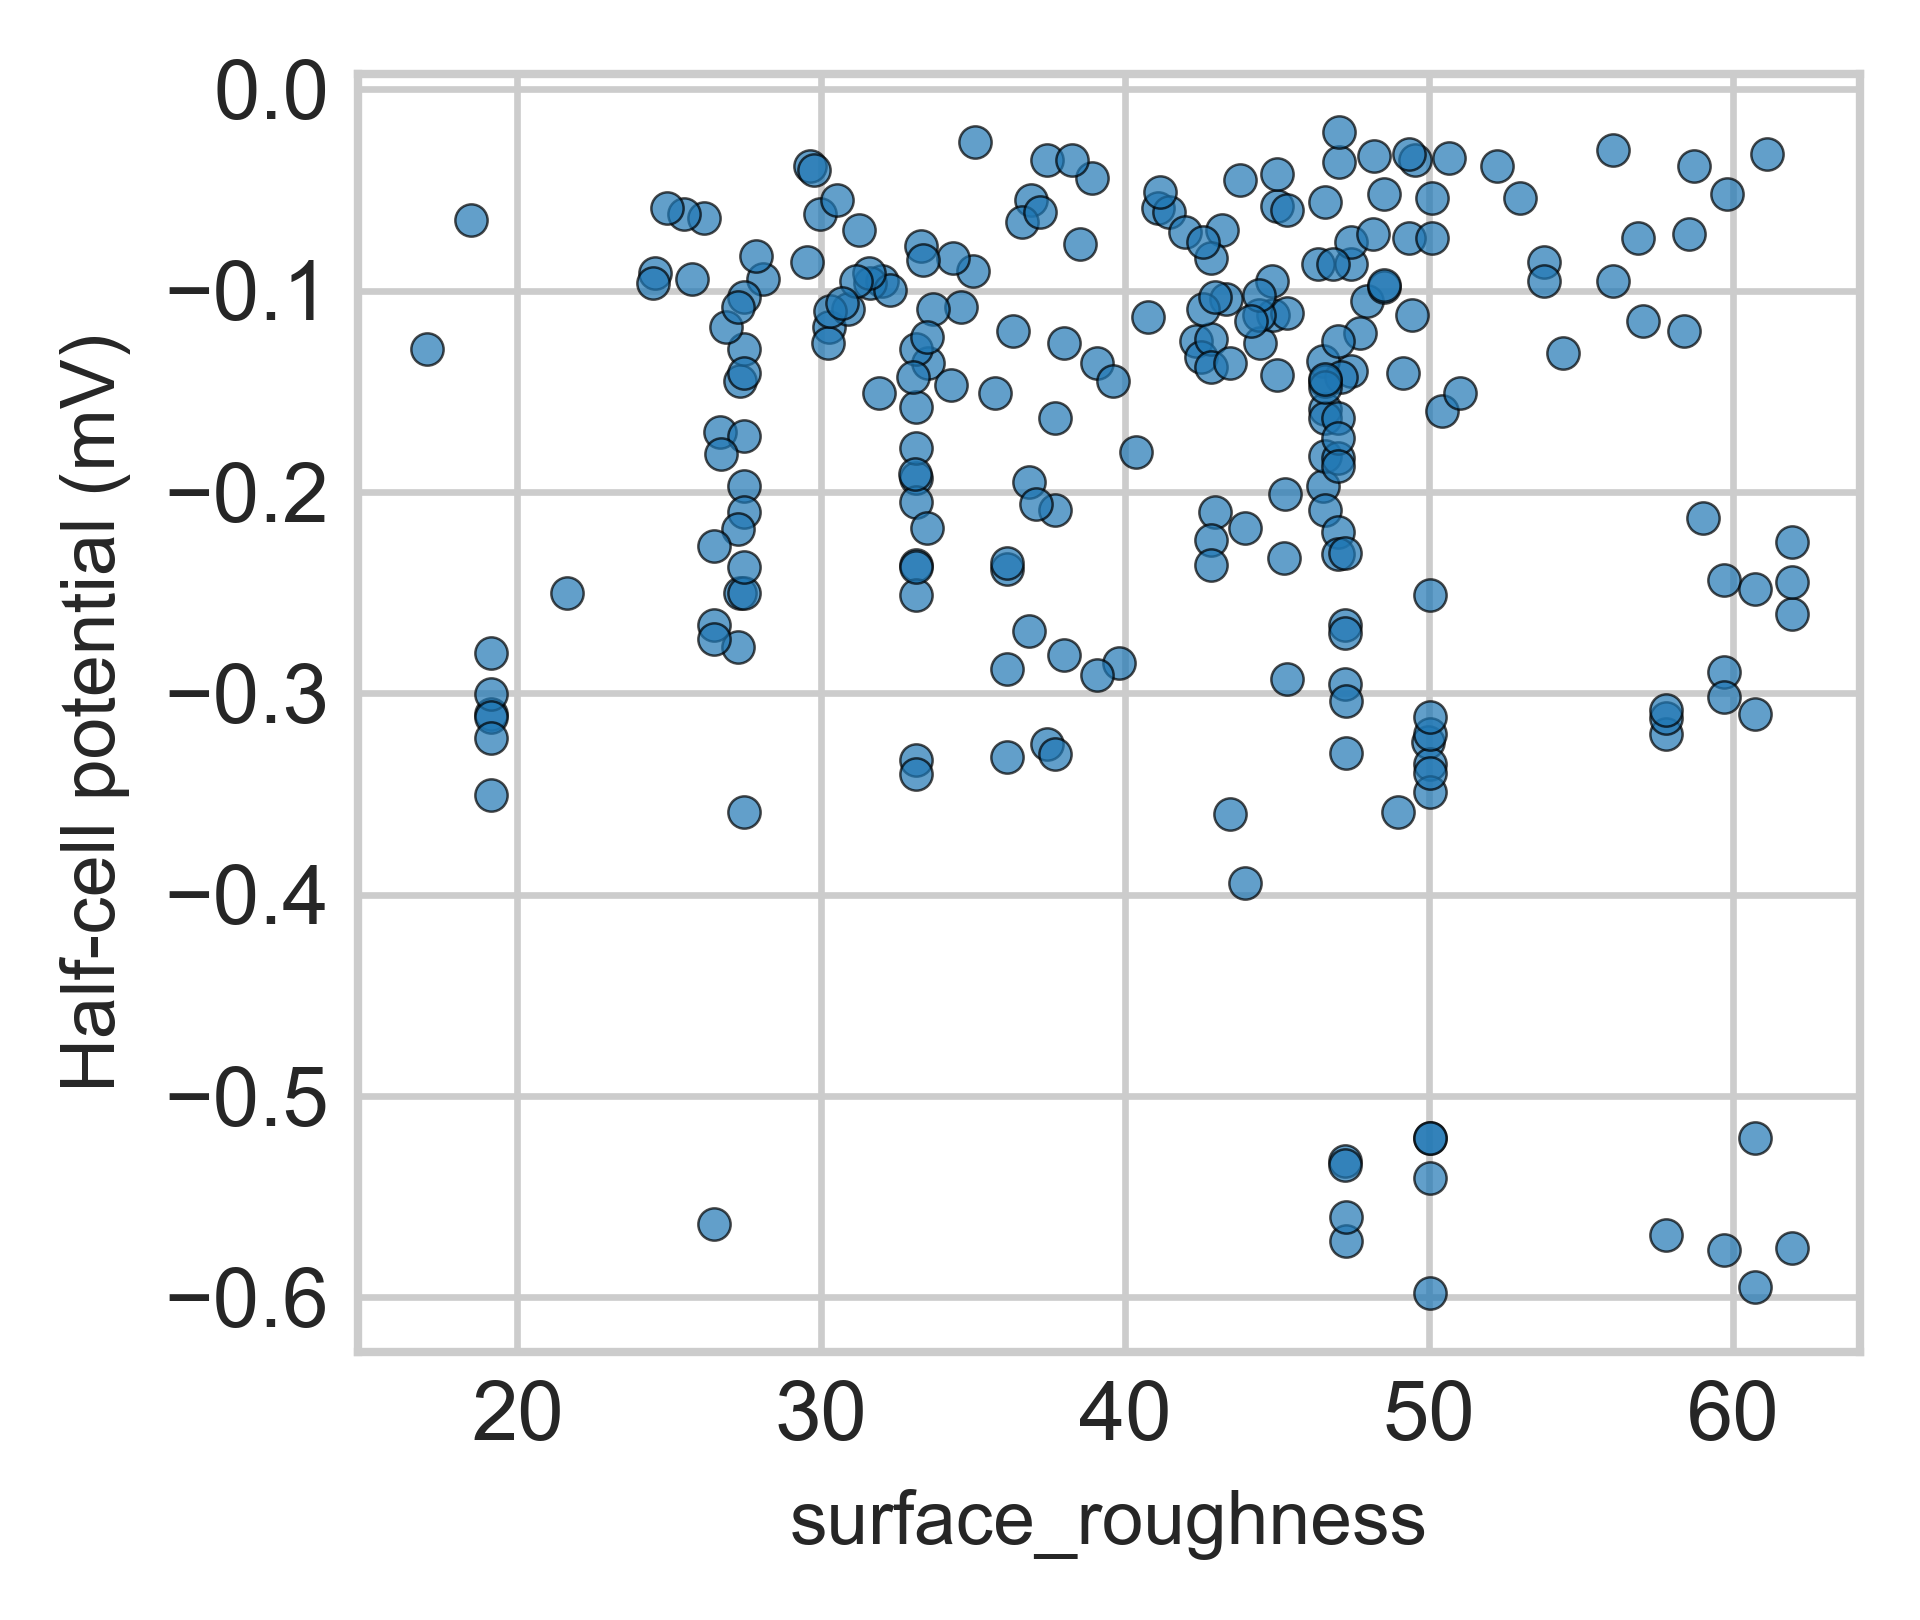

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# ======================
# 0. Load data
# ======================
path = fr"F:\ALL Works\wiley q1 corrosioin\data\data.csv"
df = pd.read_csv(path)
df.dropna(inplace=True)

X = df.drop(columns=['half-cell_potential_v'])
y = df['half-cell_potential_v']

# ======================
# 1. Train/Test split
# ======================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ======================
# 2. Scaling (KNN requires scaling)
# ======================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ======================
# 3. KNN Regressor + GridSearchCV
# ======================
knn = KNeighborsRegressor()

param_grid = {
    'n_neighbors': list(range(1, 21)),
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

grid_search = GridSearchCV(
    estimator=knn,
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    verbose=1
)

grid_search.fit(X_train_scaled, y_train)
best_knn = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best CV R²:", grid_search.best_score_)

# ======================
# 4. Predictions & residuals
# ======================
y_pred = best_knn.predict(X_test_scaled)
residuals = y_test - y_pred

# ======================
# 5. Evaluation
# ======================
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("\nKNN Regression Test Performance:")
print("-------------------------------")
print("R²:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

# ======================
# 9. Plot 4: Scatter plots of each feature vs target
# ======================
plt.style.use("seaborn-v0_8-whitegrid")

for col in X.columns:
    plt.figure(figsize=(3.3, 2.8), dpi=600)

    plt.scatter(
        X[col], y,
        s=15,
        edgecolor='black',
        linewidth=0.3,
        alpha=0.7
    )

    plt.xlabel(col, fontsize=9)
    plt.ylabel("Half-cell potential (mV)", fontsize=9)

    plt.tight_layout()

    path = fr"F:\ALL Works\wiley q1 corrosioin\figure\model_wise_plot\knn_plot\{col}_vs_h_cell.svg"
    # plt.savefig(f"{col}_scatter_wiley.tiff", dpi=600, bbox_inches='tight')
    plt.savefig(path, dpi=1000, bbox_inches='tight')

    plt.show()
